# Interpretabilidade com LLM — Explicações em Linguagem Natural
## Tech Challenge Fase 2 — Projeto 1

Este notebook integra o modelo de diagnóstico (Random Forest otimizado) com uma **LLM via Groq API** (Qwen 3.8 27B) para gerar explicações em linguagem natural dos diagnósticos.

### Motivação
O SHAP (Fase 1) fornece explicabilidade técnica. Porém, médicos precisam de explicações em **linguagem natural** — não de gráficos com valores numéricos. A LLM transforma os dados do modelo em texto acionável para o profissional de saúde.

### Estrutura do notebook
1. Configuração da API Groq
2. Carregamento do modelo e dados
3. Extração de contexto clínico (features + SHAP)
4. Prompt engineering para contexto médico
5. Geração de explicações para casos reais
6. Modo interativo — perguntas sobre diagnósticos
7. Avaliação da qualidade das explicações
8. Discussão crítica

## 1. Imports e configuração

In [1]:
import sys
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from dotenv import load_dotenv
from groq import Groq

sys.path.append('../src')
from evaluation import evaluate_model

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')

# Carrega variáveis do .env
load_dotenv('../.env')

GROQ_API_KEY = os.getenv('GROQ_API_KEY')
if not GROQ_API_KEY:
    raise EnvironmentError('GROQ_API_KEY não encontrada. Verifique o arquivo .env na raiz do projeto.')

print('Variáveis carregadas com sucesso.')

Variáveis carregadas com sucesso.


## 2. Inicialização do cliente Groq

In [2]:
client = Groq(api_key=GROQ_API_KEY)

MODEL = 'qwen/qwen3.8-27b'  # Modelo disponível no Groq free tier

def chamar_llm(prompt_sistema, prompt_usuario, temperatura=0.3, max_tokens=1024):
    """
    Envia uma mensagem para a LLM e retorna a resposta em texto.
    temperatura baixa (0.3) = respostas mais consistentes e conservadoras
    """
    resposta = client.chat.completions.create(
        model=MODEL,
        messages=[
            {'role': 'system',  'content': prompt_sistema},
            {'role': 'user',    'content': prompt_usuario},
        ],
        temperature=temperatura,
        max_tokens=max_tokens,
    )
    return resposta.choices[0].message.content

# Teste de conectividade
teste = chamar_llm(
    'Você é um assistente médico.',
    'Responda em uma frase: qual é a sua função neste sistema?',
    max_tokens=100
)
print('Conexão com Groq OK.')
print(f'Resposta de teste: {teste}')

Conexão com Groq OK.
Resposta de teste: Minha função é atuar como um assistente médico, fornecendo informações e orientações de saúde de forma clara e segura.


## 3. Carregamento do modelo e dados

In [3]:
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test  = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
y_test  = pd.read_csv('../data/processed/y_test.csv').squeeze()

# Tenta carregar o modelo otimizado (notebook 05); usa o original como fallback
try:
    modelo = joblib.load('../models/random_forest_otimizado.joblib')
    print('Modelo carregado: Random Forest Otimizado (AG)')
except FileNotFoundError:
    modelo = joblib.load('../models/random_forest.joblib')
    print('Modelo carregado: Random Forest Original (Fase 1)')

print(f'Amostras de teste: {len(X_test)}')

Modelo carregado: Random Forest Otimizado (AG)
Amostras de teste: 114


## 4. Extração de contexto clínico — features + SHAP

Para cada amostra, extraímos:
- A **predição** (Maligno/Benigno) e a **probabilidade de malignidade**
- Os **valores SHAP** — quanto cada feature contribuiu para a decisão

Esses dados são formatados e enviados à LLM como contexto.

In [4]:
# Calcula SHAP para todo o conjunto de teste
explainer  = shap.TreeExplainer(modelo)
shap_exp   = explainer(X_test)
shap_malig = shap_exp[:, :, 1]  # classe Maligno

# Predições e probabilidades
y_pred      = modelo.predict(X_test)
y_prob      = modelo.predict_proba(X_test)[:, 1]  # prob. de Maligno

print('SHAP calculado para todas as amostras de teste.')
print(f'Malignos no teste: {(y_test == 1).sum()} | Benignos: {(y_test == 0).sum()}')

SHAP calculado para todas as amostras de teste.
Malignos no teste: 42 | Benignos: 72


In [5]:
# Nomes amigáveis para as features (para a LLM entender melhor)
FEATURE_NAMES_PT = {
    'radius_mean':            'Raio médio',
    'texture_mean':           'Textura média',
    'perimeter_mean':         'Perímetro médio',
    'area_mean':              'Área média',
    'smoothness_mean':        'Suavidade média',
    'compactness_mean':       'Compacidade média',
    'concavity_mean':         'Concavidade média',
    'concave points_mean':    'Pontos côncavos médios',
    'symmetry_mean':          'Simetria média',
    'fractal_dimension_mean': 'Dimensão fractal média',
    'radius_se':              'Raio (erro padrão)',
    'texture_se':             'Textura (erro padrão)',
    'perimeter_se':           'Perímetro (erro padrão)',
    'area_se':                'Área (erro padrão)',
    'smoothness_se':          'Suavidade (erro padrão)',
    'compactness_se':         'Compacidade (erro padrão)',
    'concavity_se':           'Concavidade (erro padrão)',
    'concave points_se':      'Pontos côncavos (erro padrão)',
    'symmetry_se':            'Simetria (erro padrão)',
    'fractal_dimension_se':   'Dimensão fractal (erro padrão)',
    'radius_worst':           'Raio (pior valor)',
    'texture_worst':          'Textura (pior valor)',
    'perimeter_worst':        'Perímetro (pior valor)',
    'area_worst':             'Área (pior valor)',
    'smoothness_worst':       'Suavidade (pior valor)',
    'compactness_worst':      'Compacidade (pior valor)',
    'concavity_worst':        'Concavidade (pior valor)',
    'concave points_worst':   'Pontos côncavos (pior valor)',
    'symmetry_worst':         'Simetria (pior valor)',
    'fractal_dimension_worst':'Dimensão fractal (pior valor)',
}

def formatar_contexto(idx_amostra, top_n=6):
    """
    Formata o contexto clínico de uma amostra para envio à LLM.
    idx_amostra: posição no X_test (0-based)
    """
    features  = X_test.iloc[idx_amostra]
    shap_vals = shap_malig[idx_amostra].values
    predicao  = 'Maligno' if y_pred[idx_amostra] == 1 else 'Benigno'
    confianca = y_prob[idx_amostra] if y_pred[idx_amostra] == 1 else 1 - y_prob[idx_amostra]
    real      = 'Maligno' if y_test.iloc[idx_amostra] == 1 else 'Benigno'

    # Top N features por valor SHAP absoluto — usando índice numérico corretamente
    shap_series   = pd.Series(np.abs(shap_vals), index=X_test.columns)
    top_features  = shap_series.nlargest(top_n).index

    linhas_features = []
    for feat in top_features:
        pos   = list(X_test.columns).index(feat)
        nome  = FEATURE_NAMES_PT.get(feat, feat)
        valor = features[feat]
        shap_v = shap_vals[pos]
        dire  = 'indica MALIGNIDADE' if shap_v > 0 else 'indica BENIGNIDADE'
        linhas_features.append(
            f'  • {nome}: {valor:.4f} (impacto SHAP = {shap_v:+.4f}, {dire})'
        )

    return {
        'predicao':  predicao,
        'confianca': confianca,
        'real':      real,
        'features':  '\n'.join(linhas_features),
        'acerto':    predicao == real,
    }

# Exemplo
ctx = formatar_contexto(0)
print(f"Predição: {ctx['predicao']} ({ctx['confianca']:.1%} de confiança) | Real: {ctx['real']} | Acerto: {ctx['acerto']}")
print(f"\nFeatures relevantes:\n{ctx['features']}")

Predição: Benigno (98.5% de confiança) | Real: Benigno | Acerto: True

Features relevantes:
  • Pontos côncavos (pior valor): -0.3881 (impacto SHAP = -0.0960, indica BENIGNIDADE)
  • Pontos côncavos médios: -0.5748 (impacto SHAP = -0.0896, indica BENIGNIDADE)
  • Raio médio: -0.7709 (impacto SHAP = -0.0612, indica BENIGNIDADE)
  • Textura média: -2.0060 (impacto SHAP = -0.0415, indica BENIGNIDADE)
  • Textura (pior valor): -1.6360 (impacto SHAP = -0.0381, indica BENIGNIDADE)
  • Concavidade média: -0.6625 (impacto SHAP = -0.0226, indica BENIGNIDADE)


## 5. Prompt Engineering — Sistema de prompts médicos

O **prompt do sistema** define o papel e as restrições da LLM.  
O **prompt do usuário** fornece os dados clínicos de cada caso.

In [6]:
PROMPT_SISTEMA = """
Você é um assistente especializado em apoio à interpretação de diagnósticos oncológicos.
Seu papel é traduzir os resultados de um modelo de machine learning em linguagem clínica clara
e objetiva, para auxiliar médicos na tomada de decisão.

Regras obrigatórias:
- Nunca afirme que o diagnóstico é definitivo. O modelo é uma ferramenta de apoio, não substitui avaliação clínica.
- Use terminologia médica adequada, mas sem jargões desnecessários.
- Seja direto e estruturado — médicos têm pouco tempo.
- Sempre mencione as limitações do modelo.
- Responda sempre em português do Brasil.
""".strip()


def prompt_diagnostico(contexto):
    """Gera o prompt do usuário com os dados do caso clínico."""
    return f"""
O sistema de triagem por machine learning analisou uma biópsia e produziu o seguinte resultado:

**Diagnóstico sugerido:** {contexto['predicao']}
**Confiança do modelo:** {contexto['confianca']:.1%}

**Principais características que influenciaram o diagnóstico (ordenadas por impacto):**
{contexto['features']}

Por favor, gere um laudo de apoio estruturado com:
1. **Resumo executivo** — diagnóstico e nível de confiança em 2 frases
2. **Fatores determinantes** — explique em linguagem clínica o que cada característica relevante indica
3. **Recomendação** — próximos passos sugeridos para o médico responsável
4. **Atenção** — limitações do modelo que o médico deve considerar
""".strip()


def gerar_laudo(idx_amostra, top_n=6):
    """Gera o laudo completo para uma amostra do conjunto de teste."""
    ctx    = formatar_contexto(idx_amostra, top_n=top_n)
    prompt = prompt_diagnostico(ctx)
    laudo  = chamar_llm(PROMPT_SISTEMA, prompt)
    return ctx, laudo

print('Prompts configurados.')

Prompts configurados.


## 6. Geração de laudos — casos reais

Geramos laudos para 4 casos representativos:
- **Caso 1:** tumor maligno corretamente identificado
- **Caso 2:** tumor benigno corretamente identificado
- **Caso 3:** falso positivo (benigno classificado como maligno)
- **Caso 4:** falso negativo (maligno classificado como benigno) — se houver

In [7]:
# Identifica índices dos casos de interesse
y_test_arr  = y_test.values
y_pred_arr  = y_pred

vp_idx  = np.where((y_test_arr == 1) & (y_pred_arr == 1))[0]  # Verdadeiros Positivos
vn_idx  = np.where((y_test_arr == 0) & (y_pred_arr == 0))[0]  # Verdadeiros Negativos
fp_idx  = np.where((y_test_arr == 0) & (y_pred_arr == 1))[0]  # Falsos Positivos
fn_idx  = np.where((y_test_arr == 1) & (y_pred_arr == 0))[0]  # Falsos Negativos

print(f'Verdadeiros Positivos (maligno correto): {len(vp_idx)}')
print(f'Verdadeiros Negativos (benigno correto): {len(vn_idx)}')
print(f'Falsos Positivos (benigno → maligno):    {len(fp_idx)}')
print(f'Falsos Negativos (maligno → benigno):    {len(fn_idx)}')

Verdadeiros Positivos (maligno correto): 37
Verdadeiros Negativos (benigno correto): 71
Falsos Positivos (benigno → maligno):    1
Falsos Negativos (maligno → benigno):    5


In [8]:
# Caso 1 — Maligno identificado corretamente
print('=' * 60)
print('CASO 1 — Tumor maligno (acerto do modelo)')
print('=' * 60)

ctx1, laudo1 = gerar_laudo(vp_idx[0])
print(f"Predição: {ctx1['predicao']} | Real: {ctx1['real']} | Confiança: {ctx1['confianca']:.1%}\n")
print(laudo1)

CASO 1 — Tumor maligno (acerto do modelo)


Predição: Maligno | Real: Maligno | Confiança: 100.0%

**1. Resumo Executivo**
O modelo de triagem classificou a amostra de biópsia como **Maligno** com uma pontuação de confiança de 100,0%. Esta classificação é sustentada por padrões morfológicos que indicam alta irregularidade e complexidade estrutural, sugerindo forte probabilidade de neoplasia maligna.

**2. Fatores Determinantes**
A decisão do modelo foi impulsionada primariamente por características geométricas que refletem a perda da arquitetura tecidual organizada, típica de processos neoplásicos:

*   **Irregularidade Contorno (Pontos Côncavos e Concavidade Média):** Os valores elevados de "Pontos côncavos" (1.4229) e "Concavidade média" (2.2304) indicam um contorno celular ou tecidual altamente irregular e não uniforme. Em patologia, contornos com múltiplas concavidades e protrusões são marcadores clássicos de invasividade e perda de coesão celular, frequentemente associados a células malignas.
*   **Tamanho e Variação (Raio 

In [9]:
# Caso 2 — Benigno identificado corretamente
print('=' * 60)
print('CASO 2 — Tumor benigno (acerto do modelo)')
print('=' * 60)

ctx2, laudo2 = gerar_laudo(vn_idx[0])
print(f"Predição: {ctx2['predicao']} | Real: {ctx2['real']} | Confiança: {ctx2['confianca']:.1%}\n")
print(laudo2)

CASO 2 — Tumor benigno (acerto do modelo)


Predição: Benigno | Real: Benigno | Confiança: 98.5%

**1. Resumo Executivo**
O modelo de triagem por machine learning sugere, com alta probabilidade estatística (98,5%), que a amostra analisada apresenta características histopatológicas benignas. Esta avaliação é um instrumento de apoio à decisão clínica e não substitui a análise microscópica final do patologista.

**2. Fatores Determinantes**
A classificação como "Benigno" foi impulsionada principalmente pela ausência de irregularidades morfológicas típicas de malignidade. Os principais fatores explicados pelos valores SHAP são:

*   **Ausência de Concavidades (Pontos Côncavos):** Os valores negativos para "pontos côncavos" e "concavidade média" indicam uma borda lisa e regular. Em lesões malignas, é comum observar bordas irregulares ou "dentes de serra" (concavidades), o que não foi detectado aqui.
*   **Uniformidade de Tamanho (Raio Médio):** O baixo impacto negativo no "raio médio" sugere que as células ou a estrutura da lesão pos

In [10]:
# Caso 3 — Falso Positivo (se houver) ou segundo VP
print('=' * 60)
if len(fp_idx) > 0:
    print('CASO 3 — Falso Positivo (benigno classificado como maligno)')
    print('=' * 60)
    ctx3, laudo3 = gerar_laudo(fp_idx[0])
else:
    print('CASO 3 — Segundo maligno identificado corretamente (sem FP no teste)')
    print('=' * 60)
    ctx3, laudo3 = gerar_laudo(vp_idx[1])

print(f"Predição: {ctx3['predicao']} | Real: {ctx3['real']} | Confiança: {ctx3['confianca']:.1%}\n")
print(laudo3)

CASO 3 — Falso Positivo (benigno classificado como maligno)


Predição: Maligno | Real: Benigno | Confiança: 59.4%

**1. Resumo Executivo**
O modelo de triagem classifica a amostra como **Maligno**, porém com uma confiança estatística baixa (59,4%), o que indica uma probabilidade quase equitativa entre os desfechos benigno e maligno. Devido à baixa certeza preditiva, este resultado deve ser considerado apenas como um alerta inicial e não como diagnóstico definitivo.

**2. Fatores Determinantes**
A classificação foi influenciada por sinais morfométricos conflitantes, divididos em dois grupos:

*   **Indicadores de Malignidade (Predominantes):**
    *   **Pontos côncavos médios (0.9163):** O alto impacto positivo (+0.1656) sugere uma borda irregular e complexa, característica comum em lesões invasivas.
    *   **Raio médio (0.2612):** O impacto positivo (+0.1330) pode indicar heterogeneidade dimensional ou crescimento assimétrico, embora o valor absoluto dependa da escala de normalização dos dados de entrada.
    *   **Concavidade média (0.3016):**

In [11]:
# Caso 4 — Falso Negativo (se houver) — o mais crítico clinicamente
print('=' * 60)
if len(fn_idx) > 0:
    print('CASO 4 — Falso Negativo (MALIGNO NÃO DETECTADO — crítico!)')
    print('=' * 60)
    ctx4, laudo4 = gerar_laudo(fn_idx[0])
    print(f"Predição: {ctx4['predicao']} | Real: {ctx4['real']} | Confiança: {ctx4['confianca']:.1%}\n")
    print(laudo4)
else:
    print('CASO 4 — Nenhum falso negativo no conjunto de teste.')
    print('O modelo não deixou nenhum tumor maligno passar despercebido.')
    print('=' * 60)

CASO 4 — Falso Negativo (MALIGNO NÃO DETECTADO — crítico!)


Predição: Benigno | Real: Maligno | Confiança: 96.0%

**1. Resumo Executivo**
O modelo de inteligência artificial classificou a amostra de biópsia como **Benigna**, com um nível de confiança estatística de 96,0%. Esta sugestão é baseada em padrões morfológicos que indicam ausência de atipia celular significativa e arquitetura tecidual organizada.

**2. Fatores Determinantes**
A classificação benigna foi impulsionada principalmente pelas seguintes características histológicas e morfológicas:

*   **Textura (Média e Pior Valor):** Os valores negativos de textura sugerem uma homogeneidade tecidual e uma distribuição uniforme das células, características típicas de tecido normal ou lesões não neoplásicas, em contraste com a heterogeneidade e desordem nuclear vistas em malignidades.
*   **Raio Médio e Erro Padrão do Raio:** O baixo valor do raio médio e a baixa variabilidade (erro padrão) indicam que as células apresentam tamanho uniforme e regular. A ausência de pleomorfismo celular (varia

## 7. Modo interativo — perguntas sobre diagnósticos

O médico pode fazer perguntas em linguagem natural sobre um caso específico.

In [12]:
def consulta_interativa(idx_amostra, pergunta_medico):
    """
    Permite ao médico fazer perguntas adicionais sobre um caso já analisado.
    """
    ctx    = formatar_contexto(idx_amostra)
    prompt = f"""
Contexto do caso:
- Diagnóstico sugerido: {ctx['predicao']} (confiança: {ctx['confianca']:.1%})
- Características relevantes:\n{ctx['features']}

Pergunta do médico: {pergunta_medico}
""".strip()

    resposta = chamar_llm(PROMPT_SISTEMA, prompt, temperatura=0.4)
    return resposta


# Exemplo de consulta interativa
resposta = consulta_interativa(
    idx_amostra=vp_idx[0],
    pergunta_medico='Quais exames complementares você recomendaria para confirmar este diagnóstico?'
)
print('Resposta da LLM:')
print(resposta)

Resposta da LLM:
**Aviso Importante:** O modelo de machine learning indicou uma probabilidade de 100% para malignidade com base nas características morfométricas fornecidas. No entanto, **nenhum algoritmo substitui a confirmação histopatológica**. A alta confiança estatística deve ser interpretada como um forte sinal de alerta para investigação imediata, mas não como diagnóstico definitivo.

Com base no perfil das características (alta concavidade e irregularidade do contorno, sugerindo bordas irregulares ou "spiculated"), recomendo a seguinte sequência de exames complementares para confirmação:

### 1. Exame de Imagem Complementar (Se ainda não realizado ou para melhor caracterização)
*   **Ultrassonografia (US) da região:** Essencial para diferenciar lesões sólidas de císticas, avaliar a vascularização (Doppler) e definir a melhor via para biópsia.
*   **Ressonância Magnética (RM) com contraste:** Se a lesão for de mama, pele ou tecido mole, a RM oferece superior contraste-soft tissu

In [13]:
# Segunda consulta — interpretação de uma feature específica
resposta2 = consulta_interativa(
    idx_amostra=vp_idx[0],
    pergunta_medico='O que significa "pontos côncavos (pior valor)" e por que ele é importante neste diagnóstico?'
)
print('Resposta da LLM:')
print(resposta2)

Resposta da LLM:
**Resposta Direta:**

"Pontos côncavos (pior valor)" refere-se à máxima irregularidade ou "entrância" detectada no contorno da lesão analisada pelo modelo. Neste caso, o valor de **1.4229** representa a medida mais extrema de não-uniformidade na borda da massa.

**Importância Clínica neste Caso:**

1.  **Indicador de Irregularidade Marginal:** Em oncologia, bordas irregulares, anguladas ou com concavidades profundas são frequentemente associadas a crescimento desordenado e invasivo (características malignas), diferentemente das bordas lisas e bem definidas típicas de lesões benignas.
2.  **Alto Impacto Preditivo (SHAP):** Este é o **fator mais influente** na decisão do modelo (Impacto SHAP = +0.1724). Isso significa que, entre todas as características analisadas, a presença dessa concavidade extrema contribuiu mais do que qualquer outro fator para a classificação de "Maligno".
3.  **Correlação com Agressividade:** A combinação de altos valores de concavidade com um rai

## 8. Avaliação da qualidade das explicações

Usamos a própria LLM como avaliadora (*LLM-as-a-judge*) — uma técnica comum para avaliar a qualidade de respostas geradas quando não há ground truth textual.

In [14]:
PROMPT_AVALIADOR = """
Você é um especialista em qualidade de sistemas de apoio à decisão médica.
Avalie o laudo médico a seguir em 4 critérios, dando uma nota de 1 a 5 para cada um.
Responda APENAS no formato JSON indicado, sem texto adicional.
""".strip()


def avaliar_laudo(laudo):
    prompt = f"""
Laudo a avaliar:
\"\"\"
{laudo}
\"\"\"

Avalie nos seguintes critérios (nota de 1 a 5):
- clareza: linguagem clara e acessível para médicos
- completude: cobre todos os aspectos relevantes do caso
- seguranca: deixa claro que é apoio à decisão, não diagnóstico definitivo
- acionabilidade: fornece orientações práticas e concretas

Responda APENAS neste formato JSON:
{{"clareza": X, "completude": X, "seguranca": X, "acionabilidade": X, "justificativa": "texto breve"}}
""".strip()

    import json
    resp = chamar_llm(PROMPT_AVALIADOR, prompt, temperatura=0.1, max_tokens=300)
    try:
        return json.loads(resp)
    except:
        return {'erro': resp}


# Avalia os laudos dos casos 1 e 2
av1 = avaliar_laudo(laudo1)
av2 = avaliar_laudo(laudo2)

print('=== Avaliação — Caso 1 (Maligno) ===')
for k, v in av1.items():
    print(f'  {k}: {v}')

print('\n=== Avaliação — Caso 2 (Benigno) ===')
for k, v in av2.items():
    print(f'  {k}: {v}')

=== Avaliação — Caso 1 (Maligno) ===
  clareza: 5
  completude: 4
  seguranca: 5
  acionabilidade: 5
  justificativa: O laudo apresenta linguagem técnica precisa e acessível, estrutura lógica clara e destaca fortemente a natureza de apoio à decisão, mitigando riscos de interpretação equivocada. A acionabilidade é alta, com recomendações específicas de validação e próximos passos clínicos. A completude é ligeiramente reduzida pela ausência de dados clínicos do paciente ou contexto da biópsia, focando apenas nas métricas do modelo.

=== Avaliação — Caso 2 (Benigno) ===
  clareza: 5
  completude: 4
  seguranca: 5
  acionabilidade: 5
  justificativa: O laudo é extremamente claro, utilizando terminologia médica precisa mas acessível. A segurança é reforçada por avisos explícitos sobre a natureza de apoio à decisão e limitações do modelo. A acionabilidade é alta, com passos concretos de revisão e acompanhamento. A completude é levemente penalizada por não detalhar métricas específicas de per

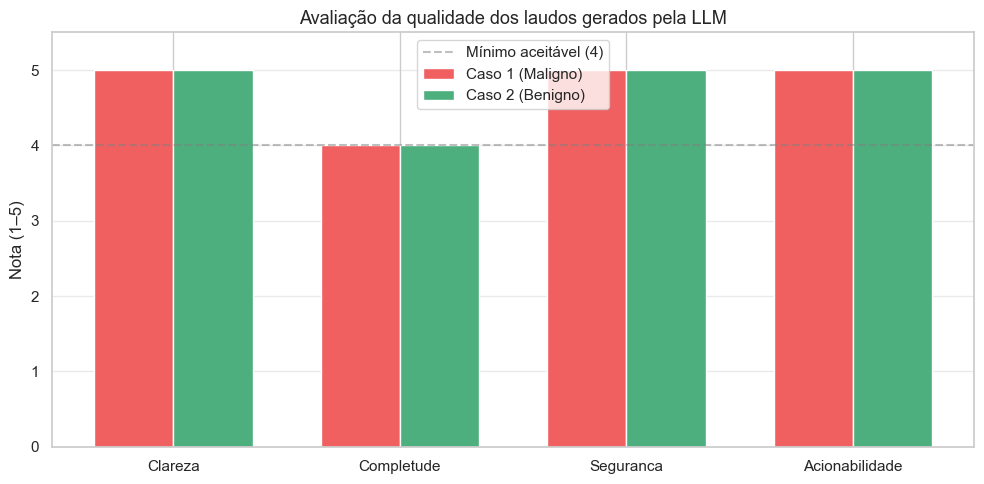

In [15]:
# Visualização das avaliações
criterios = ['clareza', 'completude', 'seguranca', 'acionabilidade']

notas_c1 = [av1.get(c, 0) for c in criterios]
notas_c2 = [av2.get(c, 0) for c in criterios]

x = np.arange(len(criterios))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, notas_c1, width, label='Caso 1 (Maligno)', color='#f06060', edgecolor='white')
ax.bar(x + width/2, notas_c2, width, label='Caso 2 (Benigno)', color='#4caf7d', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels([c.capitalize() for c in criterios])
ax.set_ylim(0, 5.5)
ax.set_ylabel('Nota (1–5)')
ax.set_title('Avaliação da qualidade dos laudos gerados pela LLM', fontsize=13)
ax.axhline(y=4, color='gray', linestyle='--', alpha=0.5, label='Mínimo aceitável (4)')
ax.legend()
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('../reports/figures/24_avaliacao_llm.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Discussão crítica

### O que a LLM agrega além do SHAP?

O SHAP fornece valores numéricos de impacto — úteis para cientistas de dados, mas pouco intuitivos para médicos. A LLM transforma esses números em **texto clínico contextualizado**, conectando os valores de características de biópsia com sua interpretação oncológica.

### Técnicas de prompt engineering utilizadas

| Técnica | Aplicação neste notebook |
|---------|-------------------------|
| **Role prompting** | "Você é um assistente especializado em..." — define contexto e tom |
| **Few-shot via estrutura** | Estrutura numerada (1. Resumo, 2. Fatores...) guia o formato da resposta |
| **Temperatura baixa** | 0.3 para laudos — respostas mais conservadoras e consistentes |
| **Restrições explícitas** | "Nunca afirme diagnóstico definitivo" — segurança clínica |
| **LLM-as-a-judge** | A própria LLM avalia a qualidade dos laudos que gerou |

### Limitações importantes

- A LLM pode **alucinar** — gerar explicações plausíveis mas incorretas clinicamente
- As explicações devem ser validadas por médicos antes de uso em produção
- O modelo base é treinado em dados de um único centro — a LLM não corrige vieses do modelo
- Em produção, seria necessário avaliar a qualidade das explicações com médicos reais, não apenas LLM-as-a-judge